<a href="https://colab.research.google.com/github/riyen-perdana/wrangler-project/blob/main/Wrangler_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [108]:
# Data Analysis
import pandas as pd
import numpy as np

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

In [109]:
# Datasheet yang digunakan adalah df yang sudah di download dari project sebelumnya yang sebelumnya bernama df_1 (dataframe)
# digunakan kembali pada bagian ini agar tidak mengulang terlalu banyak kode.

url = 'https://raw.githubusercontent.com/riyen-perdana/pelatihan-digital-skola/refs/heads/main/df.csv'
df = pd.read_csv(url)  # Membaca dataset dari file CSV
df.head(5)

,listing_id,brand,body_type,year,fuel,transmission,engine_cc,mileage_km,price_juta,segment
0,101238,Suzuki,SUV,2022.0,Petrol,Manual,1000,40151.0,113.6,Mass Market
1,101073,Mazda,Pickup,2023.0,Diesel,Manual,1000,25645.0,201.6,Mass Market
2,100454,Lexus,MPV,2023.0,Diesel,Manual,1500,11637.0,659.6,Premium
3,100363,Lexus,SUV,2018.0,Petrol,Manual,1500,135280.0,244.4,Premium
4,101018,Kia,Pickup,2015.0,Diesel,Automatic,1500,93530.0,58.6,Value Brand


In [110]:
# Asumsi tingkat inflasi tahunan Indonesia (untuk latihan saja)
inflation_rates = {
    2012: 0.043, 2013: 0.064, 2014: 0.064, 2015: 0.036,
    2016: 0.030, 2017: 0.038, 2018: 0.032, 2019: 0.028,
    2020: 0.017, 2021: 0.016, 2022: 0.041,
}

def adjust_price(row):
    year = row['year']

    # Kalau tahun kosong (NaN), kembalikan harga asli tanpa penyesuaian
    if pd.isna(year):
        return row['price_juta']

    year = int(year)
    value = row['price_juta']

    # Kalau sudah tahun 2023, tidak perlu disesuaikan
    if year >= 2023:
        return value

    # inflasi dari tahun produksi sampai 2022
    for y in range(year, 2023):
        rate = inflation_rates.get(y, 0.0)
        value = value * (1 + rate)
    return round(value, 2)

In [111]:
df['adjusted_price_juta'] = df.apply(adjust_price, axis=1)
df[['brand','year','price_juta','adjusted_price_juta']].head(10)

,brand,year,price_juta,adjusted_price_juta
0,Suzuki,2022.0,113.6,118.26
1,Mazda,2023.0,201.6,201.60
2,Lexus,2023.0,659.6,659.60
3,Lexus,2018.0,244.4,278.89
4,Kia,2015.0,58.6,74.07
5,Honda,2019.0,83.4,92.22
6,Audi,2019.0,320.6,354.50
7,BMW,2022.0,397.6,413.90
8,Honda,NaN,81.4,81.40
9,Mazda,2018.0,107.1,122.22


In [112]:
df[['brand','year','price_juta','adjusted_price_juta']].head()

,brand,year,price_juta,adjusted_price_juta
0,Suzuki,2022.0,113.6,118.26
1,Mazda,2023.0,201.6,201.60
2,Lexus,2023.0,659.6,659.60
3,Lexus,2018.0,244.4,278.89
4,Kia,2015.0,58.6,74.07


 **Kenapa `adjusted >= price`?** Karena kita membawa harga lama ke nilai tahun 2023
  (mengalikan `1 + inflasi`), jadi harga yang disesuaikan selalu **≥** harga asli.
 Untuk mobil tahun 2023 keduanya sama.

## SOAL No.1
Tampilkan **median** `adjusted_price_juta` untuk **setiap `segment`**,
urutkan dari terbesar ke terkecil.

In [113]:
# Untuk melihat adjusted_price_juta bisa dilakukan proses matematika
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1300 entries, 0 to 1299
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   listing_id           1300 non-null   int64  
 1   brand                1300 non-null   object 
 2   body_type            1300 non-null   object 
 3   year                 1285 non-null   float64
 4   fuel                 1300 non-null   object 
 5   transmission         1278 non-null   object 
 6   engine_cc            1300 non-null   int64  
 7   mileage_km           1282 non-null   float64
 8   price_juta           1300 non-null   float64
 9   segment              1300 non-null   object 
 10  adjusted_price_juta  1300 non-null   float64
dtypes: float64(4), int64(2), object(5)
memory usage: 111.8+ KB


In [114]:
# Tampilkan Median adjusted_price untuk setiap segment, urutkan dari yang terbesar ke yang terkecil
df.groupby('segment')['adjusted_price_juta'].median().sort_values(ascending=False).reset_index(name='median_adjusted_price')

,segment,median_adjusted_price
0,Premium,256.70
1,Mass Market,77.20
2,Value Brand,75.61


## SOAL No.2
Tampilkan **jumlah record** untuk setiap `brand`, urutkan **descending**.

In [115]:
df.head()

,listing_id,brand,body_type,year,fuel,transmission,engine_cc,mileage_km,price_juta,segment,adjusted_price_juta
0,101238,Suzuki,SUV,2022.0,Petrol,Manual,1000,40151.0,113.6,Mass Market,118.26
1,101073,Mazda,Pickup,2023.0,Diesel,Manual,1000,25645.0,201.6,Mass Market,201.60
2,100454,Lexus,MPV,2023.0,Diesel,Manual,1500,11637.0,659.6,Premium,659.60
3,100363,Lexus,SUV,2018.0,Petrol,Manual,1500,135280.0,244.4,Premium,278.89
4,101018,Kia,Pickup,2015.0,Diesel,Automatic,1500,93530.0,58.6,Value Brand,74.07


In [116]:
# Tampilkan jumlah record untuk setiap brand dan diurutkan secara descending
df.groupby("brand").size().sort_values(ascending=False).reset_index(name="jumlah_record")

,brand,jumlah_record
0,Honda,102
1,Mercedes-Benz,101
2,Suzuki,95
3,BMW,94
4,Mazda,93
5,Mitsubishi,90
6,Volvo,90
7,Hyundai,89
8,Audi,84
9,Kia,82


## SOAL No.3
Tampilkan **rata-rata harga** (`price_juta`) untuk setiap `fuel`.
Apakah rata-rata di sini bisa menyesatkan? Kenapa?

In [117]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1300 entries, 0 to 1299
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   listing_id           1300 non-null   int64  
 1   brand                1300 non-null   object 
 2   body_type            1300 non-null   object 
 3   year                 1285 non-null   float64
 4   fuel                 1300 non-null   object 
 5   transmission         1278 non-null   object 
 6   engine_cc            1300 non-null   int64  
 7   mileage_km           1282 non-null   float64
 8   price_juta           1300 non-null   float64
 9   segment              1300 non-null   object 
 10  adjusted_price_juta  1300 non-null   float64
dtypes: float64(4), int64(2), object(5)
memory usage: 111.8+ KB


In [118]:
# Menampilkan Rata rata harga price_juta untuk setiap fuel
df.groupby('fuel')['price_juta'].mean()

,price_juta
fuel,
Diesel,147.245143
Electric,138.325000
Hybrid,147.541176
LPG,162.494286
Petrol,134.717278


In [119]:
df.groupby('fuel')['price_juta'].agg(['count', 'mean', 'median', 'std', 'min', 'max'])
# Distribusinya skew ke kanan di semua kategori, dikarenakan mean lebih tinggi dari median
# Jadi ada mobil mahal yang menarik mean ke atas

,count,mean,median,std,min,max
fuel,,,,,,
Diesel,350,147.245143,92.80,149.280984,15.6,703.8
Electric,108,138.325000,95.05,121.491151,20.3,629.7
Hybrid,153,147.541176,110.10,140.147757,24.5,705.8
LPG,35,162.494286,89.80,162.730866,19.9,626.6
Petrol,654,134.717278,92.15,121.420851,15.6,728.0


## SOAL No.4
Adakah hubungan antara `mileage_km` dan `price_juta`? Hitung **korelasi**-nya
dan tampilkan **scatter plot**.

In [120]:
korelasi = df['mileage_km'].corr(df['price_juta'])
print("Korelasi antara mileage_km dan price_juta:", korelasi)
print(f"Korelasi dihitung dari 1.282 data, karena 18 data dengan mileage_km kosong tidak diikutsertakan")

Korelasi antara mileage_km dan price_juta: -0.5027495367022554
Korelasi dihitung dari 1.282 data, karena 18 data dengan mileage_km kosong tidak diikutsertakan


In [121]:
print(f"Ya, ada hubungan negatif dengan kekuatan sedang (r = -0,503): semakin tinggi jarak tempuh, harga mobil cenderung semakin rendah.")

Ya, ada hubungan negatif dengan kekuatan sedang (r = -0,503): semakin tinggi jarak tempuh, harga mobil cenderung semakin rendah.


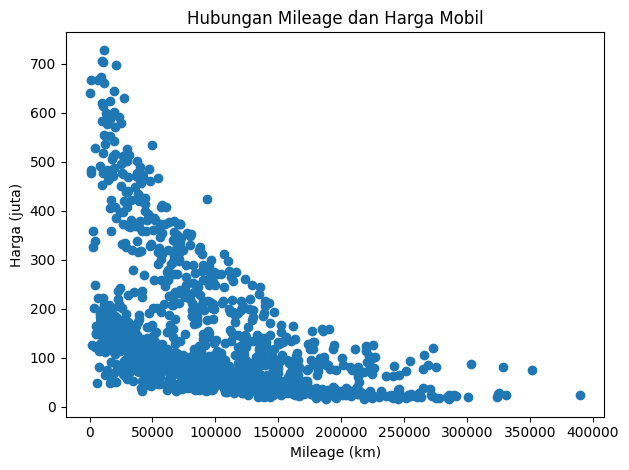

In [122]:
import matplotlib.pyplot as plt

plt.scatter(df['mileage_km'], df['price_juta'])
plt.title('Hubungan Mileage dan Harga Mobil')
plt.xlabel('Mileage (km)')
plt.ylabel('Harga (juta)')
plt.tight_layout()
plt.show()

## SOAL No.5
Buat tabel: untuk tiap `segment`, tampilkan **jumlah mobil**, **harga rata-rata**,
dan **rata-rata kilometer**. Segmen mana yang paling mahal rata-rata?

In [123]:
tabel = df.groupby('segment').agg(
    jumlah_mobil=('price_juta', 'size'),
    harga_rata_rata=('price_juta', 'mean'),
    km_rata_rata=('mileage_km', 'mean')
).sort_values('harga_rata_rata', ascending=False).round(2)

display(tabel)

,jumlah_mobil,harga_rata_rata,km_rata_rata
segment,,,
Premium,444,262.22,95019.09
Mass Market,604,78.17,98877.55
Value Brand,252,76.19,96333.02


In [124]:
termahal = tabel['harga_rata_rata'].idxmax()
harga = tabel.loc[termahal, 'harga_rata_rata']

print(f"Segment yang paling mahal adalah {termahal} dengan harga rata-rata {harga} juta")

Segment yang paling mahal adalah Premium dengan harga rata-rata 262.22 juta
